# Paper figure: UMAP by screen type (ENRICO)

ENRICO labels RICO screens by UI function rather than app domain. The main overview groups its 20 native topics into eight documented macro-types to keep the palette readable. A second small-multiple view retains every native ENRICO topic without displaying 20 competing colors at once. The macro-type mapping is an analysis choice, not an ENRICO ground-truth field.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.neighbors import NearestNeighbors

from paper_embedding_analysis import DEFAULT_EMBEDDINGS_DIR, available_embedding_ids, fit_umap, load_embeddings, output_dir, read_enrico_topics

sns.set_theme(context="paper", style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300})

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RANDOM_STATE = 42
OUTPUT_DIR = output_dir("paper_umap_screen_type_enrico")
TOPIC_TO_MACRO = {
    "login": "Authentication & forms", "form": "Authentication & forms",
    "list": "Lists & feeds", "news": "Lists & feeds",
    "gallery": "Media & gallery", "mediaplayer": "Media & gallery", "camera": "Media & gallery",
    "menu": "Navigation & search", "search": "Navigation & search", "maps": "Navigation & search",
    "profile": "Profile & settings", "settings": "Profile & settings",
    "modal": "Overlay & communication", "chat": "Overlay & communication",
    "tutorial": "Onboarding & legal", "terms": "Onboarding & legal",
    "editor": "Editing & utility", "calculator": "Editing & utility", "bare": "Editing & utility", "other": "Editing & utility",
}
MACRO_ORDER = list(dict.fromkeys(TOPIC_TO_MACRO.values()))

In [3]:
topics = read_enrico_topics()
available = available_embedding_ids(DEFAULT_EMBEDDINGS_DIR)
matched = topics[topics["screen_id"].isin(available)].copy()
missing = topics[~topics["screen_id"].isin(available)]
assert set(matched["topic"]) <= set(TOPIC_TO_MACRO)
matched["screen_type"] = matched["topic"].map(TOPIC_TO_MACRO)
ids, X = load_embeddings(matched["screen_id"], DEFAULT_EMBEDDINGS_DIR, description="Loading ENRICO screens")
vector_order = pd.DataFrame({"screen_id": ids, "row": np.arange(len(ids))})
screens = matched.merge(vector_order, on="screen_id", validate="one_to_one").sort_values("row").reset_index(drop=True)
coords, pca = fit_umap(X, random_state=RANDOM_STATE)
screens[["umap_1", "umap_2"]] = coords
display(screens.groupby(["screen_type", "topic"]).size().rename("screens").to_frame())
print(f"Matched {len(screens):,}/{len(topics):,} ENRICO screens; {len(missing):,} have no local embedding.")

Loading ENRICO screens: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1342/1342 [00:01<00:00, 1327.79it/s]


screens
screen_type             topic               
Authentication & forms  form              95
                        login            127
Editing & utility       bare              71
                        calculator         5
                        editor            18
                        other             42
Lists & feeds           list             249
                        news              52
Media & gallery         camera             8
                        gallery          131
                        mediaplayer       32
Navigation & search     maps               9
                        menu              71
                        search            29
Onboarding & legal      terms             34
                        tutorial         152
Overlay & communication chat              11
                        modal             64
Profile & settings      profile           60
                        settings          82

Matched 1,342/1,460 ENRICO screens; 118 have no local embedding.


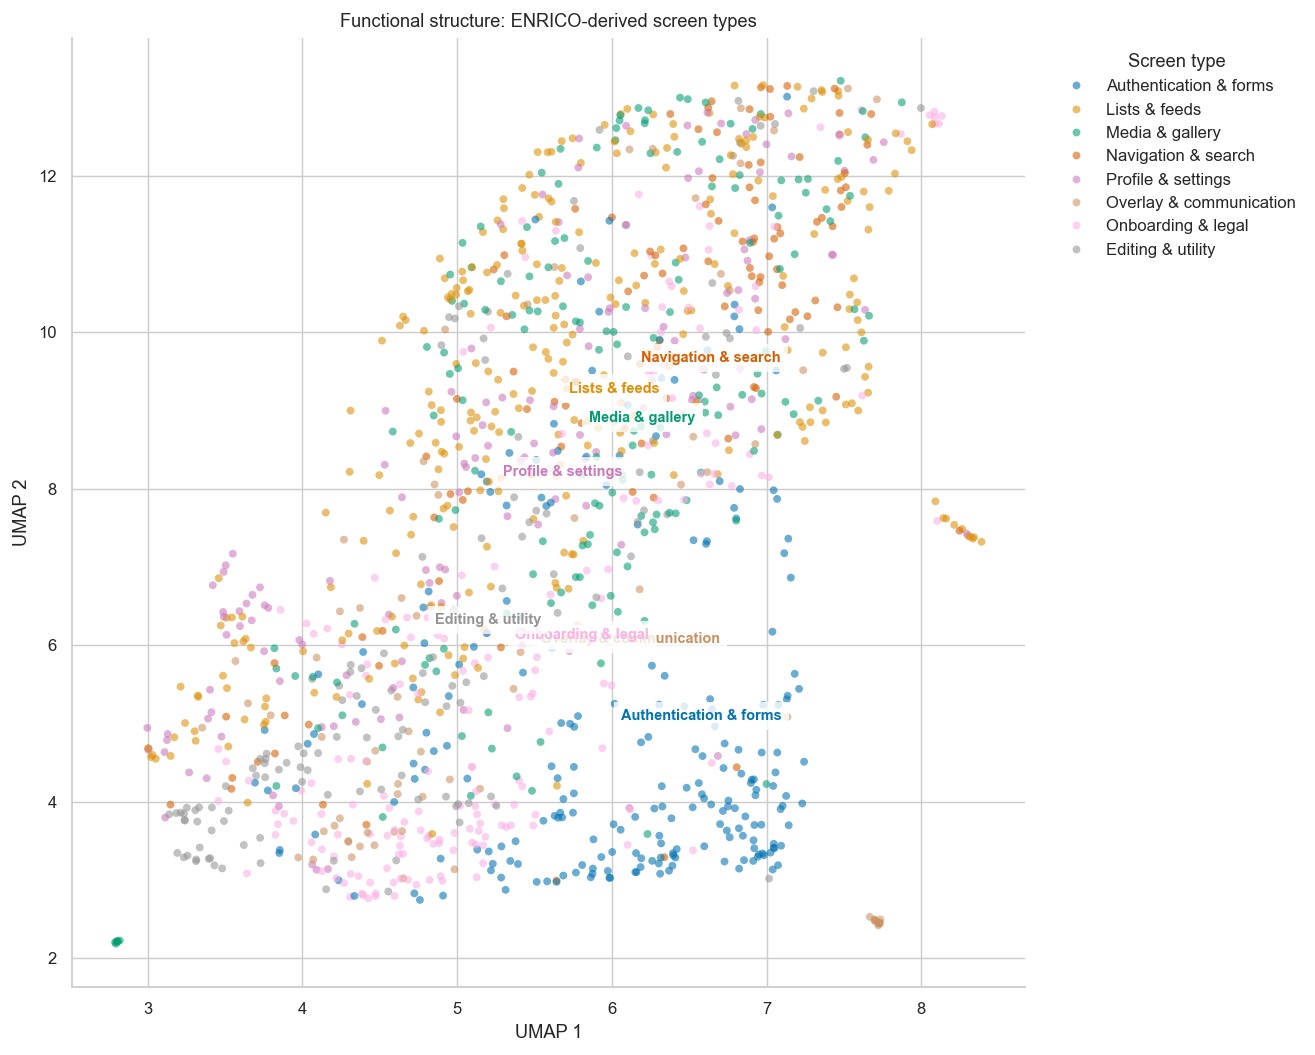

In [4]:
palette = dict(zip(MACRO_ORDER, sns.color_palette("colorblind", len(MACRO_ORDER))))
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
sns.scatterplot(data=screens, x="umap_1", y="umap_2", hue="screen_type", hue_order=MACRO_ORDER, palette=palette, s=19, alpha=0.58, linewidth=0, rasterized=True, ax=ax)
centroids = screens.groupby("screen_type")[["umap_1", "umap_2"]].mean()
for screen_type, point in centroids.loc[MACRO_ORDER].iterrows():
    ax.annotate(screen_type, point, color=palette[screen_type], fontsize=8, weight="bold", bbox={"fc": "white", "ec": "none", "alpha": 0.78})
ax.set(title="Functional structure: ENRICO-derived screen types", xlabel="UMAP 1", ylabel="UMAP 2")
ax.legend(title="Screen type", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine(ax=ax)
fig.savefig(OUTPUT_DIR / "enrico_macro_screen_type_umap.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "enrico_macro_screen_type_umap.pdf", bbox_inches="tight")
plt.show()

## Native ENRICO topics without a 20-color overview

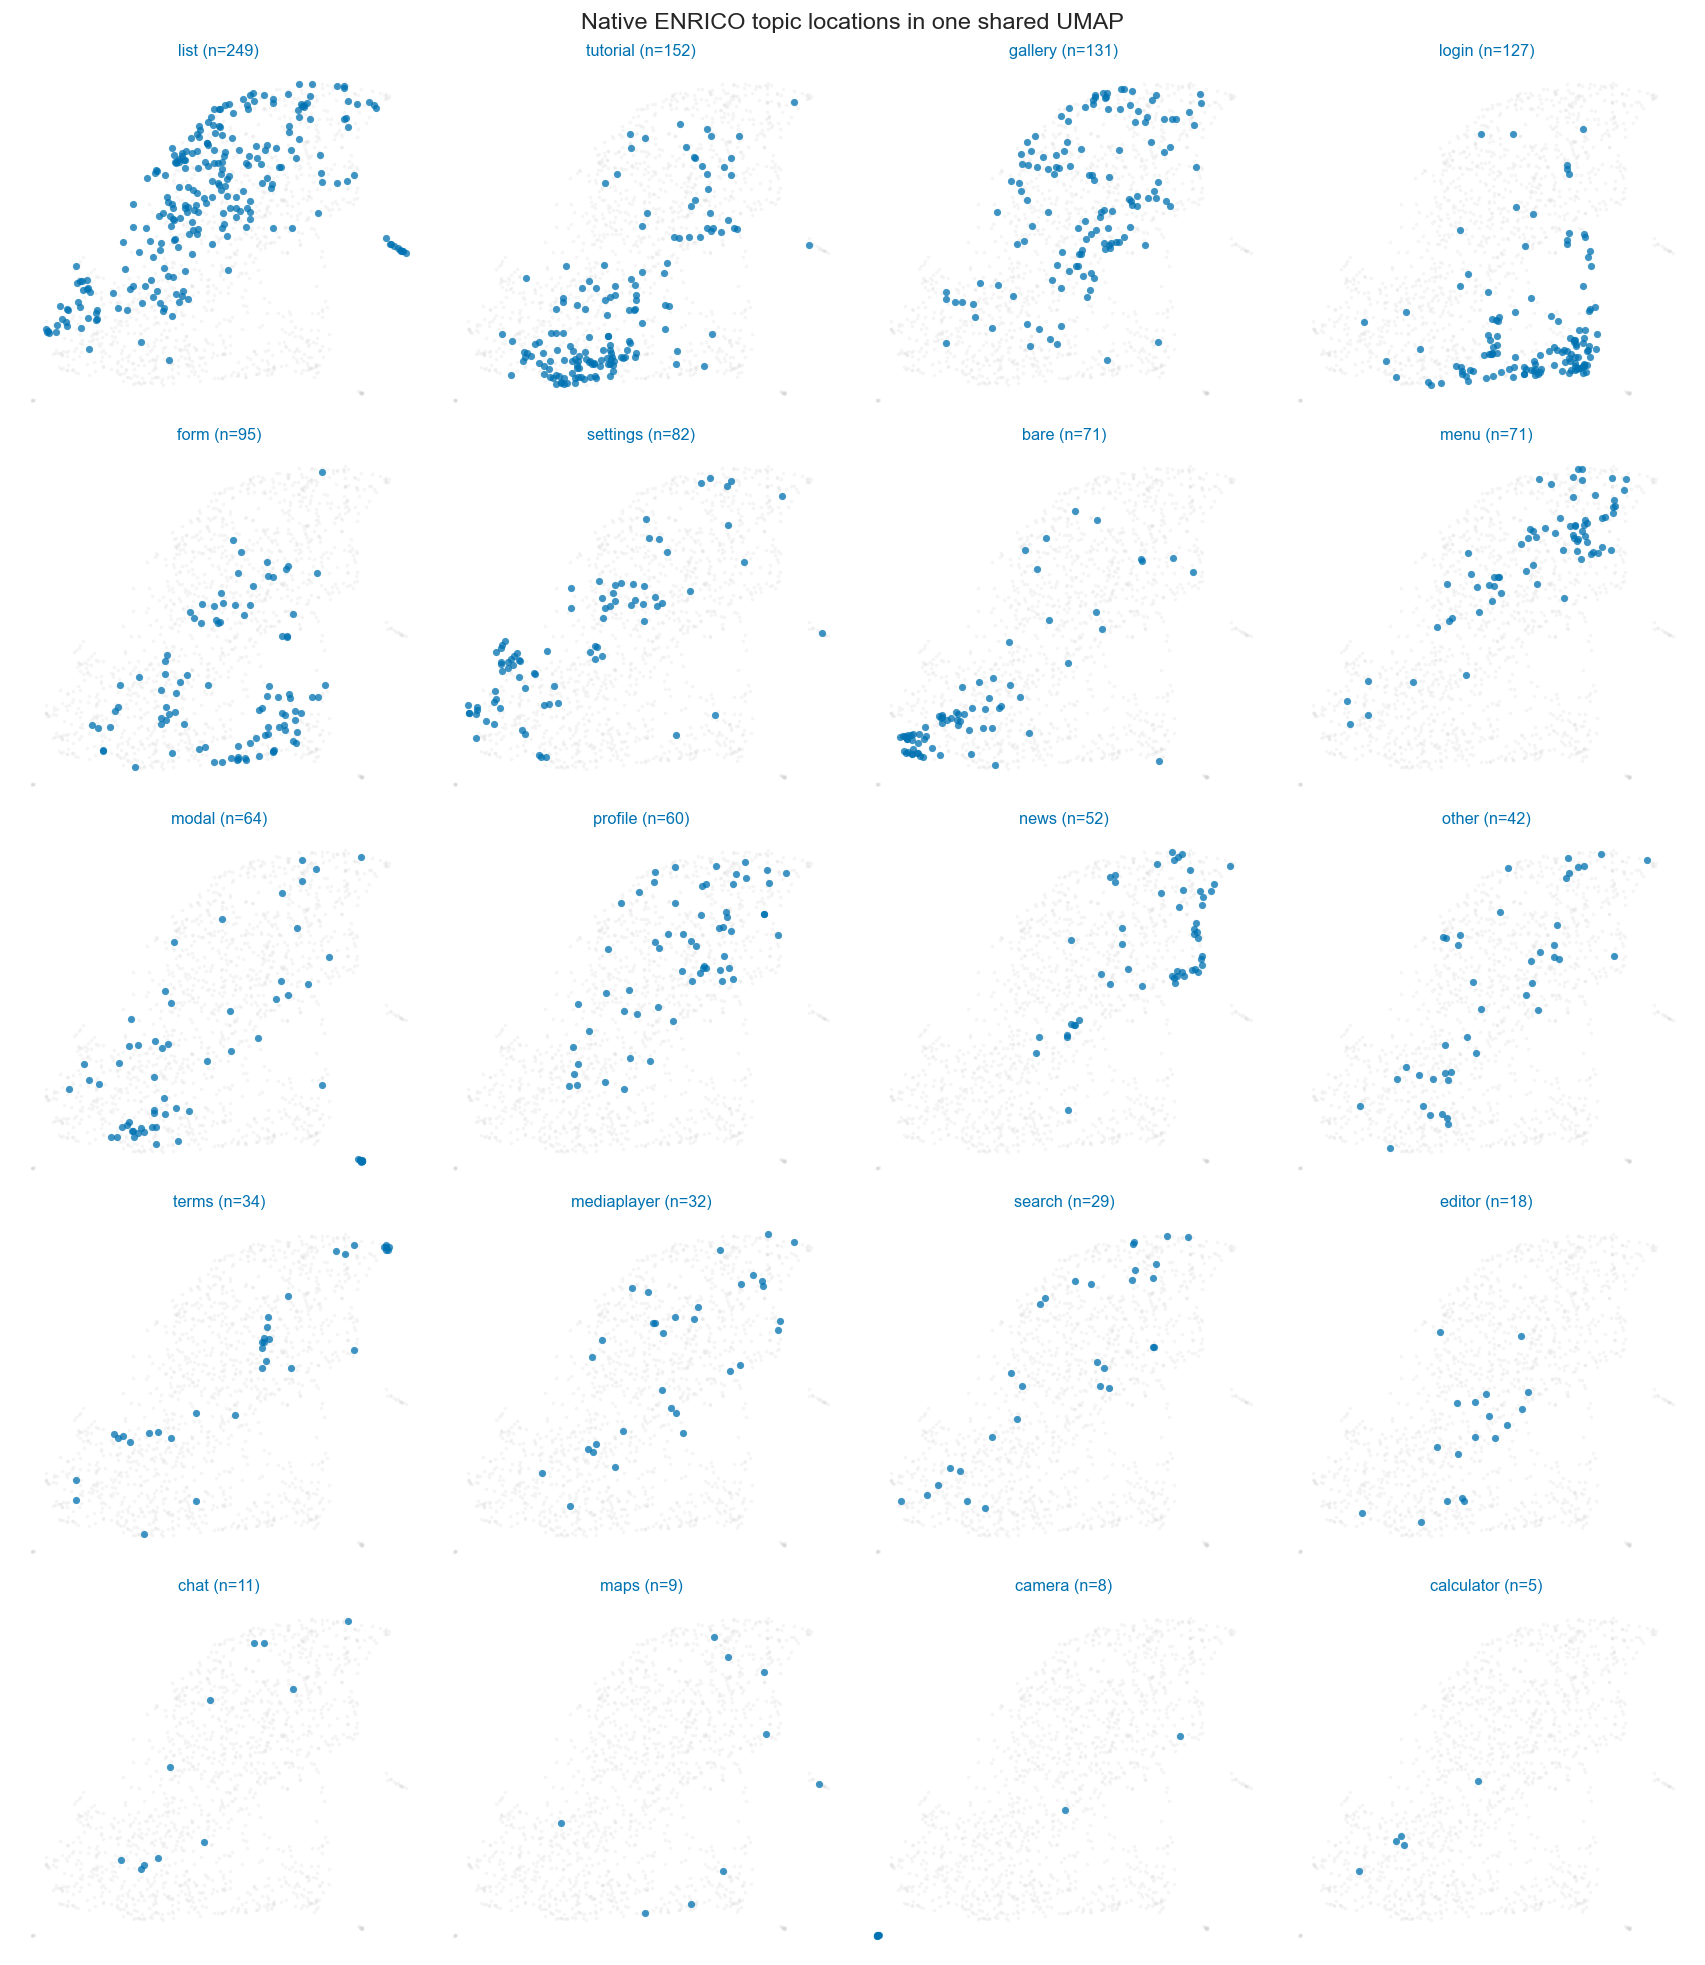

In [5]:
topic_order = screens["topic"].value_counts().index.tolist()
fig, axes = plt.subplots(5, 4, figsize=(13, 15), sharex=True, sharey=True, constrained_layout=True)
for ax, topic in zip(axes.ravel(), topic_order):
    focus = screens[screens["topic"] == topic]
    ax.scatter(screens["umap_1"], screens["umap_2"], s=4, color="#cccccc", alpha=0.18, linewidths=0, rasterized=True)
    ax.scatter(focus["umap_1"], focus["umap_2"], s=16, color="#0072B2", alpha=0.75, linewidths=0, rasterized=True)
    ax.set_title(f"{topic} (n={len(focus)})", fontsize=9, color="#0072B2")
    ax.set(xticks=[], yticks=[], xlabel="", ylabel="")
    sns.despine(ax=ax, left=True, bottom=True)
fig.suptitle("Native ENRICO topic locations in one shared UMAP", fontsize=13)
fig.savefig(OUTPUT_DIR / "enrico_native_topics_small_multiples.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "enrico_native_topics_small_multiples.pdf", bbox_inches="tight")
plt.show()

In [6]:
neighbor_model = NearestNeighbors(n_neighbors=11, metric="cosine").fit(X)
neighbors = neighbor_model.kneighbors(X, return_distance=False)[:, 1:]
metric_rows = []
for label_name in ["screen_type", "topic"]:
    labels = screens[label_name].to_numpy()
    purity = (labels[neighbors] == labels[:, None]).mean(axis=1)
    chance = float((pd.Series(labels).value_counts(normalize=True) ** 2).sum())
    metric_rows.append({"labeling": label_name, "10-NN purity": purity.mean(), "frequency chance": chance})
display(pd.DataFrame(metric_rows).style.format({"10-NN purity": "{:.3f}", "frequency chance": "{:.3f}"}))
screens.to_csv(OUTPUT_DIR / "enrico_screen_type_umap.csv", index=False)

,labeling,10-NN purity,frequency chance
0,screen_type,0.416,0.144
1,topic,0.348,0.089
